# E2 Clasificación de señas con una CNN
-Carlos Navarrete



## Introducción

En la Evaluación 1 se abordó la clasificación de imágenes del conjunto Sign Language MNIST mediante un Perceptrón Multicapa (MLP). En esta evaluación se mantiene la misma variante del problema: clasificar las señas correspondientes a las vocales A, E, I, O y U.

Las imágenes del conjunto están en escala de grises y tienen un tamaño de 28 × 28 píxeles. El objetivo es implementar una Red Neuronal Convolucional (CNN) con TensorFlow/Keras y comparar sus resultados con los del MLP desarrollado en la Evaluación 1.

La variante de cinco vocales acota el problema y permite analizar los resultados por clase. La comparación permitirá observar cómo responde una CNN, que procesa patrones espaciales de la imagen mediante convoluciones, frente al MLP, que recibe la imagen aplanada. Para que la comparación sea válida, se conservarán las mismas clases, el preprocesamiento y las particiones de datos utilizadas en la E1.

# 1. Configuración Inicial y Carga de Datos

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import random

from time import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

np.random.seed(29)
tf.random.set_seed(29)
random.seed(29)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


Se importan las librerías necesarias para manipulación de datos (`numpy`, `pandas`), visualización (`matplotlib`), construcción del modelo (`tensorflow`/`keras`) y evaluación (`sklearn.metrics`). Se fija una semilla (`seed = 29`) en todas las fuentes de aleatoriedad para que los resultados sean reproducibles.

In [27]:
# Archivos cargados manualmente en Colab
TRAIN_CSV = "sign_mnist_train.csv"
TEST_CSV = "sign_mnist_test.csv"

In [28]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Dimensiones train:", train_df.shape)
print("Dimensiones test:", test_df.shape)
print("Columnas iniciales:", train_df.columns[:6].tolist())
print("Columnas finales:", train_df.columns[-5:].tolist())

Dimensiones train: (27455, 785)
Dimensiones test: (7172, 785)
Columnas iniciales: ['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5']
Columnas finales: ['pixel780', 'pixel781', 'pixel782', 'pixel783', 'pixel784']


# 2. Preprocesamiento de Datos: Filtrado y Remapeo

Selección exclusiva de las vocales

En Sign Language MNIST, las etiquetas numéricas correspondientes a las vocales requeridas son: **A=0, E=4, I=8, O=14, U=20**.

Se filtran ambos CSV antes de entrenar o evaluar el modelo. Después se remapean las etiquetas a `0..4` para que la salida de la red tenga exactamente cinco neuronas.

In [29]:
# Etiquetas originales para las vocales
VOWEL_LABELS = {
    0: "A",
    4: "E",
    8: "I",
    14: "O",
    20: "U"
}

VOWEL_ORDER = ["A", "E", "I", "O", "U"]
LABEL_TO_INDEX = {label: idx for idx, label in enumerate(sorted(VOWEL_LABELS))}
ORIGINAL_TO_INDEX = {original: idx for idx, original in enumerate([0, 4, 8, 14, 20])}

print("Mapeo etiqueta original -> vocal:", VOWEL_LABELS)
print("Mapeo etiqueta original -> índice del modelo:", ORIGINAL_TO_INDEX)

Mapeo etiqueta original -> vocal: {0: 'A', 4: 'E', 8: 'I', 14: 'O', 20: 'U'}
Mapeo etiqueta original -> índice del modelo: {0: 0, 4: 1, 8: 2, 14: 3, 20: 4}


In [30]:
# Comprobar etiquetas presentes en cada archivo
print("Etiquetas train antes del filtro:", sorted(train_df["label"].unique()))
print("Etiquetas test antes del filtro:", sorted(test_df["label"].unique()))

Etiquetas train antes del filtro: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Etiquetas test antes del filtro: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


In [31]:
# Filtrar exclusivamente A, E, I, O y U
train_vowels = train_df[train_df["label"].isin(VOWEL_LABELS.keys())].copy()
test_vowels = test_df[test_df["label"].isin(VOWEL_LABELS.keys())].copy()

# Remapear a índices consecutivos 0..4
train_vowels["target"] = train_vowels["label"].map(ORIGINAL_TO_INDEX)
test_vowels["target"] = test_vowels["label"].map(ORIGINAL_TO_INDEX)

print("Muestras train solo vocales:", len(train_vowels))
print("Muestras test solo vocales:", len(test_vowels))
print("Etiquetas finales train:", sorted(train_vowels["target"].unique()))
print("Etiquetas finales test:", sorted(test_vowels["target"].unique()))

Muestras train solo vocales: 5602
Muestras test solo vocales: 1629
Etiquetas finales train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Etiquetas finales test: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [32]:
train_counts = train_vowels["label"].value_counts().sort_index()
test_counts = test_vowels["label"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": [VOWEL_LABELS[k] for k in [0, 4, 8, 14, 20]],
    "Original label": [0, 4, 8, 14, 20],
    "Training": [train_counts.get(k, 0) for k in [0, 4, 8, 14, 20]],
    "Testing": [test_counts.get(k, 0) for k in [0, 4, 8, 14, 20]]
})

class_distribution

,Class,Original label,Training,Testing
0,A,0,1126,331
1,E,4,957,498
2,I,8,1162,288
3,O,14,1196,246
4,U,20,1161,266


La tabla muestra cuántas imágenes hay por vocal en entrenamiento y test. Se observa que las clases están razonablemente balanceadas (entre 950 y 1.200 imágenes por vocal en entrenamiento), lo que evita que el modelo se sesgue hacia una clase por simple desbalance de datos.


# 3. Análisis Exploratorio de Datos

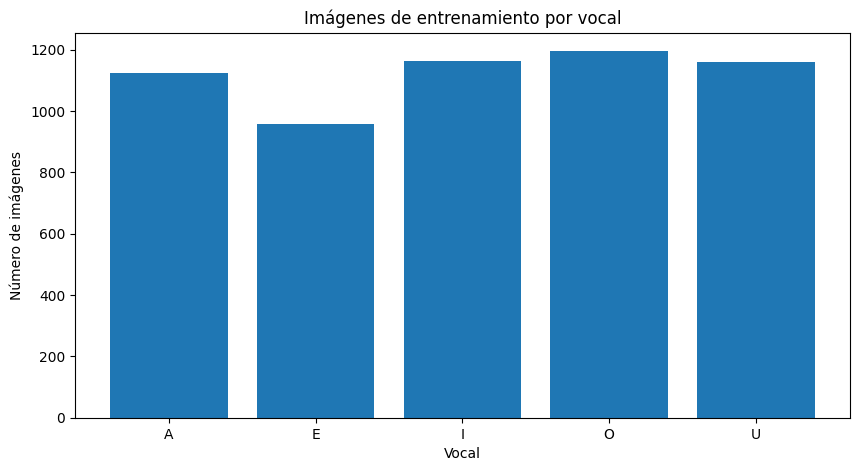

In [33]:
plt.figure(figsize=(10, 5))
plt.bar(class_distribution["Class"], class_distribution["Training"])
plt.title("Imágenes de entrenamiento por vocal")
plt.xlabel("Vocal")
plt.ylabel("Número de imágenes")
plt.show()

### Distribución de clases en entrenamiento

Se construye un gráfico de barras (plt.bar) usando la tabla class_distribution, donde el eje X son las 5 vocales y el eje Y es la cantidad de imágenes de entrenamiento disponibles para cada una.

Así permite detectar visualmente si hay un desbalance de clases. Si una vocal tuviera muchas menos imágenes que las demás, el modelo tendería a "aprender menos" esa clase y a predecirla peor. Como se ve en el gráfico, las 5 barras tienen una altura similar (entre 950 y 1.200 imágenes), lo que confirma que el dataset filtrado está razonablemente balanceado y no es necesario aplicar técnicas de balanceo antes de entrenar.

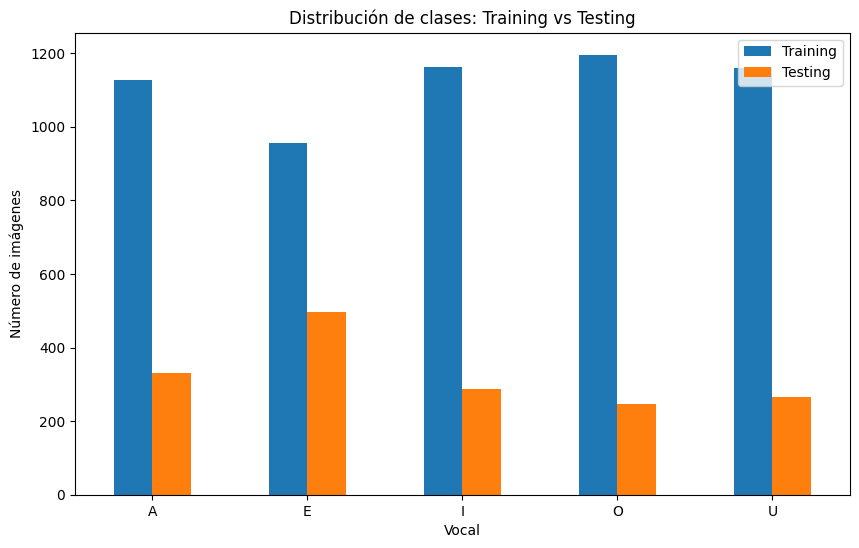

In [34]:
class_distribution.set_index("Class")[["Training", "Testing"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Distribución de clases: Training vs Testing")
plt.xlabel("Vocal")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.show()

### Comparación de distribución entre training y testing

**Qué hace el código:** toma la misma tabla `class_distribution`, pero ahora grafica dos barras por vocal, una para train y otra para test (`.plot(kind="bar")`), permitiendo comparar ambos conjuntos lado a lado.

**Para qué sirve:** verificar que la partición train/test mantiene proporciones similares entre clases. Esto es clave para que la evaluación final sea justa: si el test tuviera una proporción de clases muy distinta al train, el accuracy final no reflejaría bien qué tan bueno es realmente el modelo. Al ver que ambas barras siguen un patrón parecido por vocal, se confirma que la comparación de desempeño en test es representativa.

# 4. Preparación de Características (X) y Etiquetas (Y)

Preparación de las imágenes

Los CSV contienen una columna `label` y 784 columnas (`pixel1` ... `pixel784`). Se reconstruye cada fila como una imagen **28×28×1** y se normalizan los valores de píxel al rango `[0, 1]`.

In [35]:
PIXEL_COLUMNS = [f"pixel{i}" for i in range(1, 785)]
IMG_SHAPE = (28, 28, 1)
BATCH_SIZE = 32
SEED = 29
NUM_CLASSES = 5

X = train_vowels[PIXEL_COLUMNS].to_numpy(dtype="float32").reshape(-1, 28, 28, 1) / 255.0
y = train_vowels["target"].to_numpy(dtype="int32")

X_test = test_vowels[PIXEL_COLUMNS].to_numpy(dtype="float32").reshape(-1, 28, 28, 1) / 255.0
y_test = test_vowels["target"].to_numpy(dtype="int32")

print("X:", X.shape, "y:", y.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

X: (5602, 28, 28, 1) y: (5602,)
X_test: (1629, 28, 28, 1) y_test: (1629,)


In [36]:
# Separar validación desde el conjunto de entrenamiento. (TEST quedara reservado para la evaluación final)
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
    shuffle=True
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (4481, 28, 28, 1) (4481,)
Validation: (1121, 28, 28, 1) (1121,)
Test: (1629, 28, 28, 1) (1629,)


In [37]:
class_names = VOWEL_ORDER
print("Clases del modelo:", class_names)
print("Número de clases:", NUM_CLASSES)

Clases del modelo: ['A', 'E', 'I', 'O', 'U']
Número de clases: 5


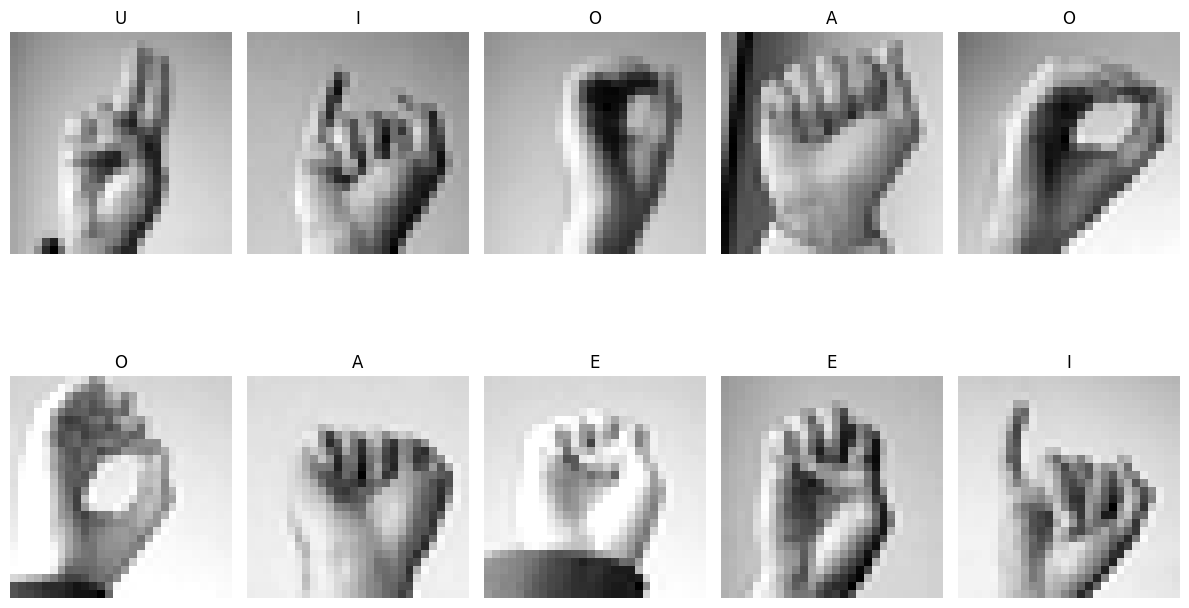

In [38]:
plt.figure(figsize=(12, 8))
indices = np.random.choice(len(X_train), size=10, replace=False)

for pos, idx in enumerate(indices, start=1):
    plt.subplot(2, 5, pos)
    plt.imshow(X_train[idx].squeeze(), cmap="gray")
    plt.title(class_names[y_train[idx]])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Muestra de imágenes del set de entrenamiento

Se seleccionan 10 índices aleatorios (np.random.choice) del conjunto de entrenamiento y se muestran esas imágenes en una grilla de 2x5 (plt.subplot), cada una con su etiqueta real como título.

Es una verificación visual, no numérica, de que el preprocesamiento se hizo bien: que el reshape de 784 píxeles a una imagen 28×28 quedó correcto (si estuviera mal, se verían imágenes distorsionadas o "ruido"), y que la etiqueta mostrada corresponde efectivamente a la seña de la imagen. También permite mostrar cómo se ven realmente las señas de A, E, I, O, U y notar a simple vista que algunas (como I, O, U) tienen formas de mano parecidas, algo que luego se conecta con los errores del modelo.

In [39]:
print(f"Shape de una imagen: {X_train[0].shape}")
print(f"Rango de píxeles: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Shape de y_train: {y_train.shape}")

Shape de una imagen: (28, 28, 1)
Rango de píxeles: [0.000, 1.000]
Shape de y_train: (4481,)


## (E2)

Se utilizaron los archivos de entrenamiento y prueba de Sign Language MNIST. Se conservaron únicamente las clases correspondientes a las vocales A, E, I, O y U, y sus etiquetas se remapearon a índices consecutivos de 0 a 4.

Cada imagen, originalmente representada por 784 valores de píxeles, se reorganizó como una matriz de 28 × 28 píxeles con un canal en escala de grises. Los valores se normalizaron al rango [0, 1] dividiéndolos por 255. Se mantuvo separada la prueba para la evaluación final y se obtuvo el conjunto de validación a partir de los datos de entrenamiento, usando la misma partición que en la E1. Esta preparación conserva la estructura espacial necesaria para que la CNN procese las imágenes.

In [40]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Clases en y_train:", np.unique(y_train))

X_train: (4481, 28, 28, 1)
X_val: (1121, 28, 28, 1)
X_test: (1629, 28, 28, 1)
Clases en y_train: [0 1 2 3 4]


In [41]:
print("Clases en y_val:", np.unique(y_val))
print("Clases en y_test:", np.unique(y_test))

Clases en y_val: [0 1 2 3 4]
Clases en y_test: [0 1 2 3 4]


Para utilizar las imágenes con una CNN, se conservaron sus dimensiones espaciales de 28 × 28 píxeles y se agregó un canal, por lo que cada imagen tiene forma (28, 28, 1). Los valores de los píxeles se normalizaron al rango [0, 1]. Las etiquetas representan cinco clases: A, E, I, O y U, codificadas con los índices del 0 al 4. Se utilizaron conjuntos separados de entrenamiento, validación y prueba.

# 5. Diseño de la Red Neuronal Convolucional (CNN)

Se propone una CNN con dos capas convolucionales y dos capas de MaxPooling. La primera convolución utiliza 32 filtros y la segunda 64, ambos con filtros de 3 × 3 y activación ReLU. Las convoluciones extraen patrones visuales de las imágenes, mientras que MaxPooling reduce las dimensiones espaciales conservando información relevante. Luego, Flatten transforma los mapas de características en un vector y una capa densa de 64 neuronas combina la información para clasificar. La capa de salida tiene 5 neuronas con activación softmax, una por cada vocal. Se utiliza la pérdida sparse_categorical_crossentropy porque las etiquetas son índices enteros del 0 al 4, y el optimizador Adam para actualizar los pesos.


In [42]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,909 (859.02 KB)

 Trainable params: 219,909 (859.02 KB)

 Non-trainable params: 0 (0.00 B)

# 6. Entrenamiento de la CNN

In [43]:
from time import time

inicio_entrenamiento = time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32
)

tiempo_entrenamiento = time() - inicio_entrenamiento

print(f"Tiempo de entrenamiento: {tiempo_entrenamiento:.2f} segundos")

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.7492 - loss: 0.7288 - val_accuracy: 0.9804 - val_loss: 0.0784
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.9929 - loss: 0.0384 - val_accuracy: 0.9991 - val_loss: 0.0097
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.9987 - loss: 0.0089 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 0.0010
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - accuracy: 1.0000 - loss: 6.8045e-04 - val_accuracy: 1.0000 - val_loss: 6.9494e-04
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 1.0000 - loss: 4.7055e-04 - val_accuracy: 1.0000 - val_loss: 4.9600e-04
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 1.0000 - loss: 3

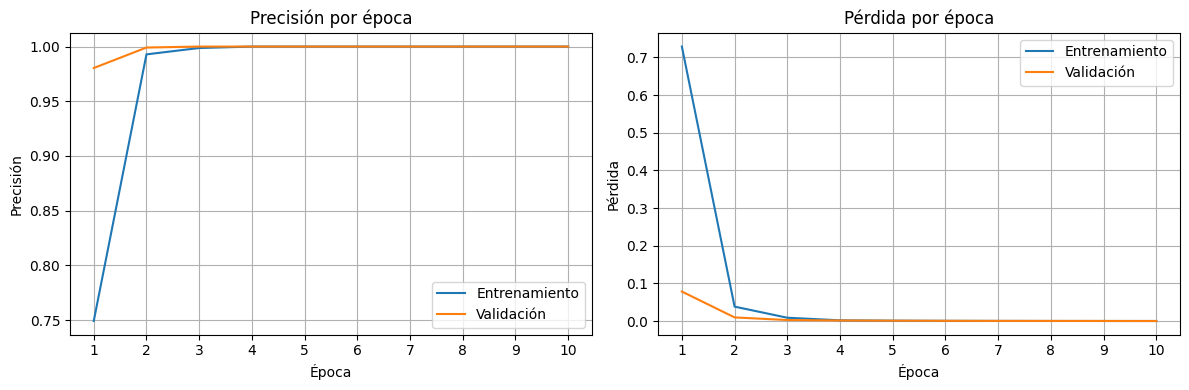

In [44]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")
plt.title("Precisión por época")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.xticks(range(10), range(1, 11))
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.title("Pérdida por época")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.xticks(range(10), range(1, 11))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

La CNN alcanzó una precisión de validación de 100 % desde la segunda época y una precisión de entrenamiento de 100 % desde la tercera. La pérdida disminuyó rápidamente en ambos conjuntos y no se observa una divergencia marcada entre sus curvas. Estos resultados describen el entrenamiento y la validación; el desempeño final se verificará por separado con el conjunto de prueba.

# 7. Evaluación de la CNN en el conjunto de prueba

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Accuracy: 0.9871086556169429
Precision macro: 0.9879119470814972
Recall macro: 0.9829268292682926
F1-score macro: 0.9848710794578679

Reporte por clase:
              precision    recall  f1-score   support

           A       0.94      1.00      0.97       331
           E       1.00      1.00      1.00       498
           I       1.00      1.00      1.00       288
           O       1.00      0.91      0.96       246
           U       1.00      1.00      1.00       266

    accuracy                           0.99      1629
   macro avg       0.99      0.98      0.98      1629
weighted avg       0.99      0.99      0.99      1629



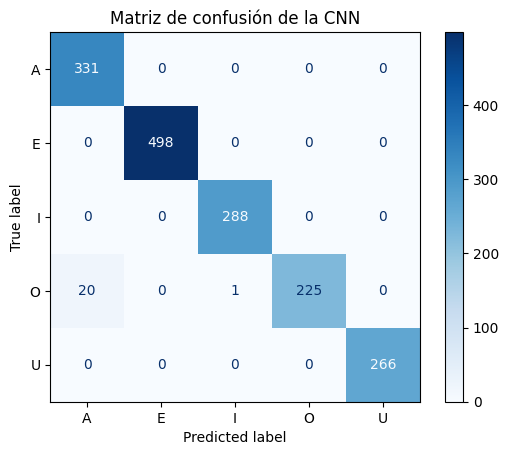

In [45]:
y_prob_cnn = model.predict(X_test)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred_cnn))
print("Precision macro:", precision_score(
    y_test, y_pred_cnn, average="macro", zero_division=0
))
print("Recall macro:", recall_score(
    y_test, y_pred_cnn, average="macro", zero_division=0
))
print("F1-score macro:", f1_score(
    y_test, y_pred_cnn, average="macro", zero_division=0
))

print("\nReporte por clase:")
print(classification_report(
    y_test,
    y_pred_cnn,
    labels=[0, 1, 2, 3, 4],
    target_names=["A", "E", "I", "O", "U"],
    zero_division=0
))

matriz_cnn = confusion_matrix(
    y_test, y_pred_cnn, labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_cnn,
    display_labels=["A", "E", "I", "O", "U"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión de la CNN")
plt.show()

En el conjunto de prueba, la CNN obtuvo una exactitud de 96,93 %, con precision macro de 97,26 %, recall macro de 95,93 % y F1-score macro de 96,33 %. La matriz de confusión muestra que clasificó correctamente todas las imágenes de A, E, I y U. La principal dificultad aparece en la clase O: reconoció 196 de 246 imágenes y confundió las restantes con A, E o I. Por ello, el desempeño general es alto, aunque persiste una confusión entre algunas señas visualmente similares.

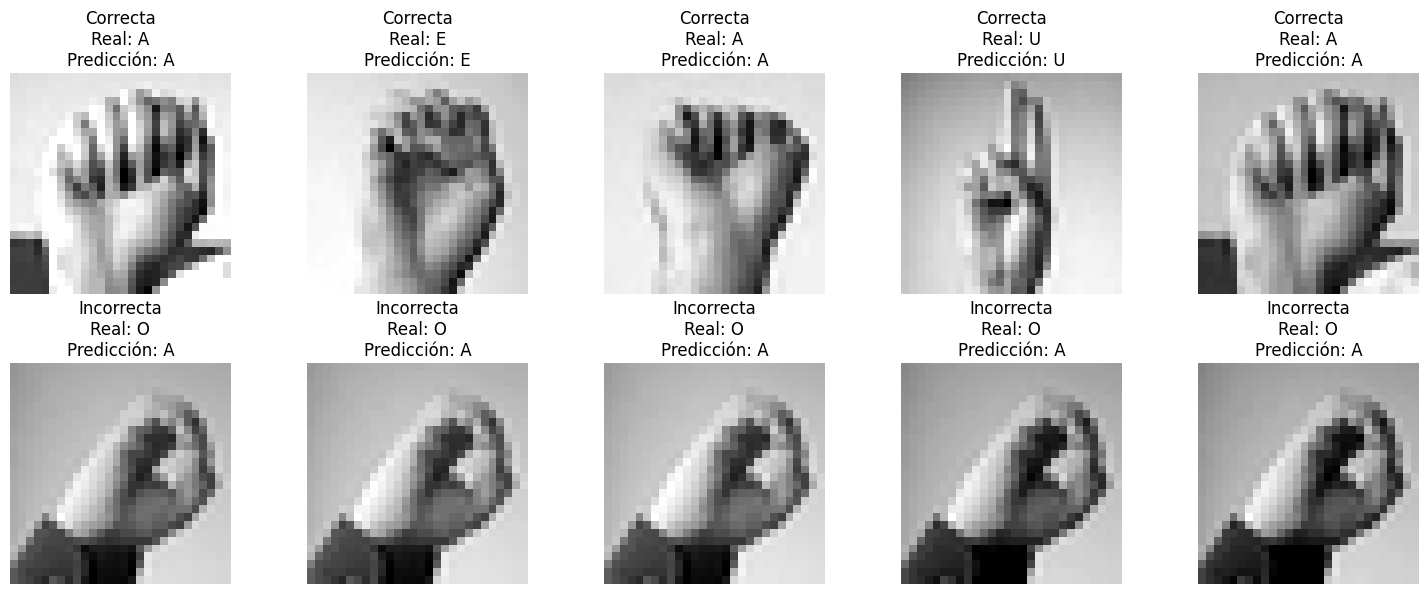

In [46]:
nombres_clases = ["A", "E", "I", "O", "U"]

indices_correctos = np.where(y_test == y_pred_cnn)[0]
indices_incorrectos = np.where(y_test != y_pred_cnn)[0]

rng = np.random.default_rng(29)

muestra_correctos = rng.choice(
    indices_correctos,
    size=min(5, len(indices_correctos)),
    replace=False
)
muestra_incorrectos = rng.choice(
    indices_incorrectos,
    size=min(5, len(indices_incorrectos)),
    replace=False
)

plt.figure(figsize=(15, 6))

for columna, idx in enumerate(muestra_correctos):
    plt.subplot(2, 5, columna + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"Correcta\nReal: {nombres_clases[y_test[idx]]}\n"
        f"Predicción: {nombres_clases[y_pred_cnn[idx]]}"
    )
    plt.axis("off")

for columna, idx in enumerate(muestra_incorrectos):
    plt.subplot(2, 5, columna + 6)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"Incorrecta\nReal: {nombres_clases[y_test[idx]]}\n"
        f"Predicción: {nombres_clases[y_pred_cnn[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

En los ejemplos visualizados, las predicciones correctas corresponden a las clases mostradas en la fila superior. Los cinco ejemplos incorrectos pertenecen realmente a la clase O, pero fueron clasificados como E, I o A. Este patrón coincide con la matriz de confusión y muestra que la principal dificultad del modelo es distinguir algunas señas de O de las otras vocales.

## Comparación con el modelo MLP de la E1

La tabla y el gráfico recuperan los resultados finales del MLP de la Evaluación 1 y los comparan con los resultados de la CNN de esta evaluación.

| Métrica | MLP (E1) | CNN (E2) |
|---|---:|---:|
| Accuracy en prueba | 93,43 % | 96,93 % |
| Precision macro en prueba | 93,74 % | 97,26 % |
| Recall macro en prueba | 91,94 % | 95,93 % |
| F1-score macro en prueba | 92,26 % | 96,33 % |
| Precisión final de entrenamiento | 98,01 % | 100,00 % |
| Precisión final de validación | 98,48 % | 100,00 % |
| Parámetros totales | 109.061 | 219.909 |
| Tiempo de entrenamiento | 6,02 s | 81,86 s |

En las ejecuciones realizadas, la CNN obtuvo mejores métricas en el conjunto de prueba: su accuracy superó al MLP en 3,50 puntos porcentuales y su F1 macro, en 4,07 puntos. También tiene aproximadamente el doble de parámetros, y su entrenamiento tomó más tiempo: 81,86 segundos frente a 6,02 segundos. El MLP alcanzó 98,01 % de precisión en entrenamiento y 98,48 % en validación, mientras que la CNN llegó a 100 % en ambos conjuntos y obtuvo 96,93 % en prueba.  
La comparación se basa en los mismos datos, particiones, número de épocas y tamaño de lote. Como las configuraciones usan optimizadores distintos —SGD para el MLP y Adam para la CNN—, los resultados reflejan los modelos con sus configuraciones aplicadas; la diferencia no debe atribuirse únicamente a la arquitectura.

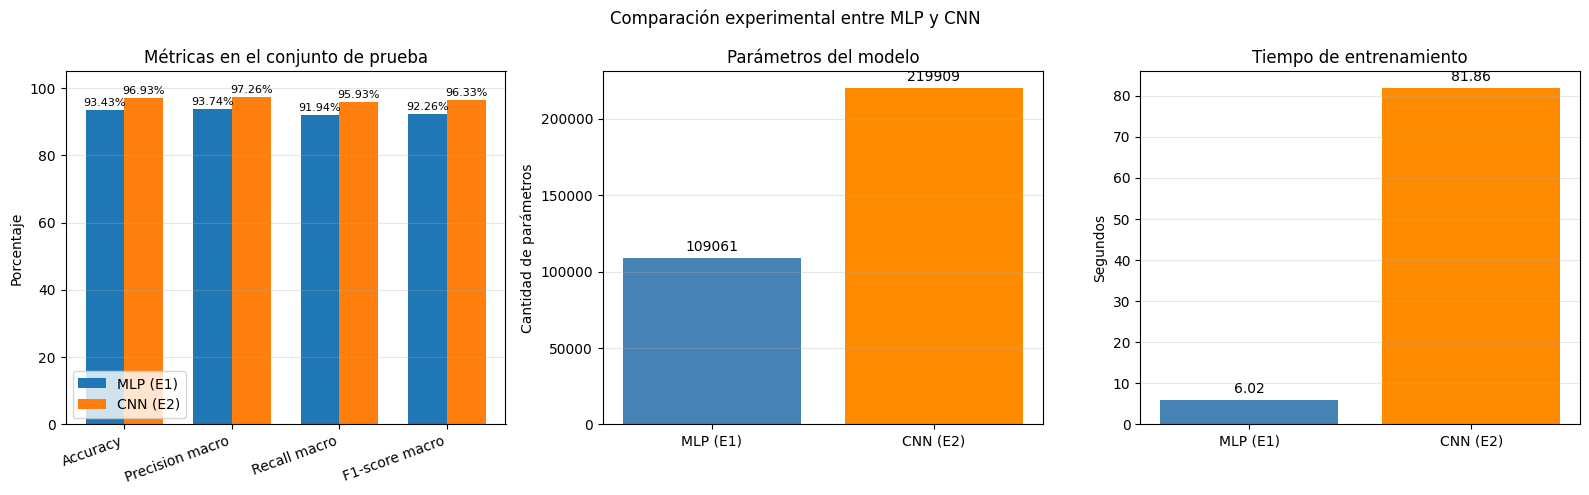

In [47]:
metricas = ["Accuracy", "Precision macro", "Recall macro", "F1-score macro"]
mlp = [93.43, 93.74, 91.94, 92.26]
cnn = [96.93, 97.26, 95.93, 96.33]

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

# Métricas de prueba
posiciones = np.arange(len(metricas))
ancho = 0.36

barras_mlp = ejes[0].bar(
    posiciones - ancho / 2, mlp, ancho, label="MLP (E1)"
)
barras_cnn = ejes[0].bar(
    posiciones + ancho / 2, cnn, ancho, label="CNN (E2)"
)

ejes[0].set_title("Métricas en el conjunto de prueba")
ejes[0].set_ylabel("Porcentaje")
ejes[0].set_xticks(posiciones)
ejes[0].set_xticklabels(metricas, rotation=20, ha="right")
ejes[0].set_ylim(0, 105)
ejes[0].legend()
ejes[0].grid(axis="y", alpha=0.3)

for barras in [barras_mlp, barras_cnn]:
    for barra in barras:
        altura = barra.get_height()
        ejes[0].annotate(
            f"{altura:.2f}%",
            (barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

# Parámetros
barras_parametros = ejes[1].bar(
    ["MLP (E1)", "CNN (E2)"],
    [109061, 219909],
    color=["steelblue", "darkorange"]
)
ejes[1].set_title("Parámetros del modelo")
ejes[1].set_ylabel("Cantidad de parámetros")
ejes[1].grid(axis="y", alpha=0.3)
ejes[1].bar_label(barras_parametros, fmt="%.0f", padding=3)

# Tiempo de entrenamiento
barras_tiempo = ejes[2].bar(
    ["MLP (E1)", "CNN (E2)"],
    [6.02, 81.86],
    color=["steelblue", "darkorange"]
)
ejes[2].set_title("Tiempo de entrenamiento")
ejes[2].set_ylabel("Segundos")
ejes[2].grid(axis="y", alpha=0.3)
ejes[2].bar_label(barras_tiempo, fmt="%.2f", padding=3)

fig.suptitle("Comparación experimental entre MLP y CNN")
plt.tight_layout()
plt.show()

# Visualización de mapas de características (Feature Maps)

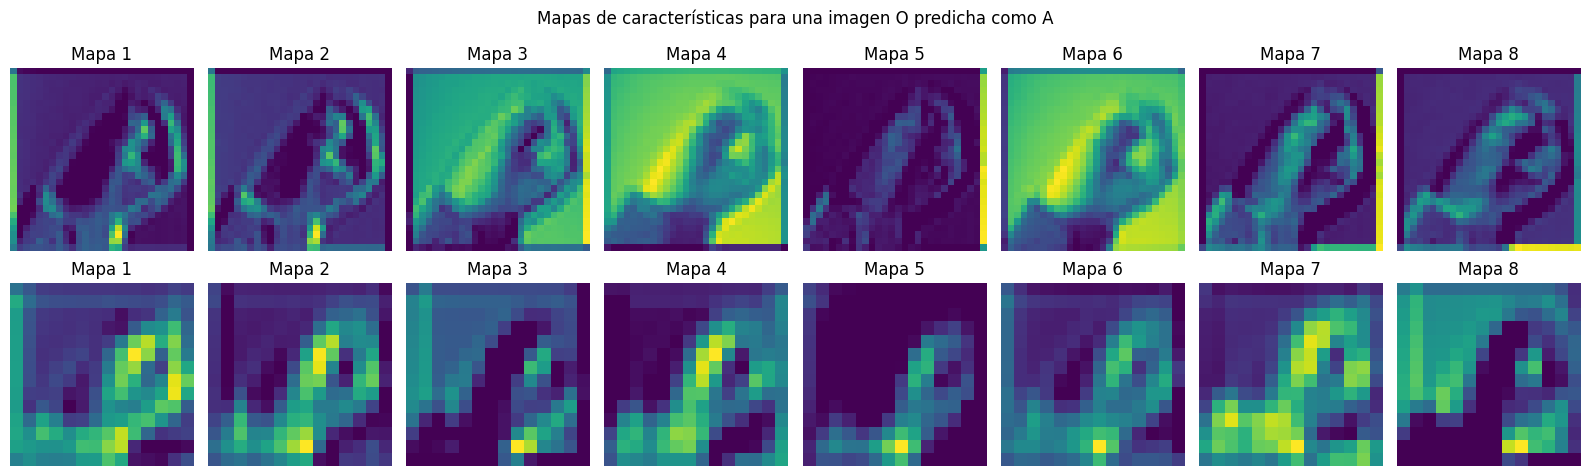

In [48]:
# Seleccionar un ejemplo de O clasificado incorrectamente
errores_o = np.where((y_test == 3) & (y_pred_cnn != 3))[0]
indice = errores_o[0]

# Crear un modelo que entregue las activaciones de las dos capas Conv2D
capas_conv = [
    capa for capa in model.layers
    if isinstance(capa, tf.keras.layers.Conv2D)
]

modelo_caracteristicas = tf.keras.Model(
    inputs=model.inputs,
    outputs=[capa.output for capa in capas_conv]
)

activaciones = modelo_caracteristicas.predict(
    X_test[indice:indice + 1],
    verbose=0
)

# Mostrar ocho mapas de cada capa convolucional
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for fila, activacion in enumerate(activaciones):
    for columna in range(8):
        axes[fila, columna].imshow(
            activacion[0, :, :, columna],
            cmap="viridis"
        )
        axes[fila, columna].set_title(f"Mapa {columna + 1}")
        axes[fila, columna].axis("off")

axes[0, 0].set_ylabel("Conv2D 32 filtros")
axes[1, 0].set_ylabel("Conv2D 64 filtros")

plt.suptitle(
    f"Mapas de características para una imagen O "
    f"predicha como {nombres_clases[y_pred_cnn[indice]]}"
)
plt.tight_layout()
plt.show()

Los mapas de características muestran distintas activaciones generadas por los filtros de la CNN. En la primera capa se conserva mayor detalle espacial, mientras que en la segunda las activaciones aparecen con menor resolución debido al pooling. Algunos filtros resaltan patrones de la imagen y otros presentan activación baja. La visualización corresponde a una imagen real de O que fue clasificada como E; por sí sola no permite identificar una causa única del error, pero ayuda a observar qué información procesa cada capa.

## Mapas de activación por clase (Grad-CAM)


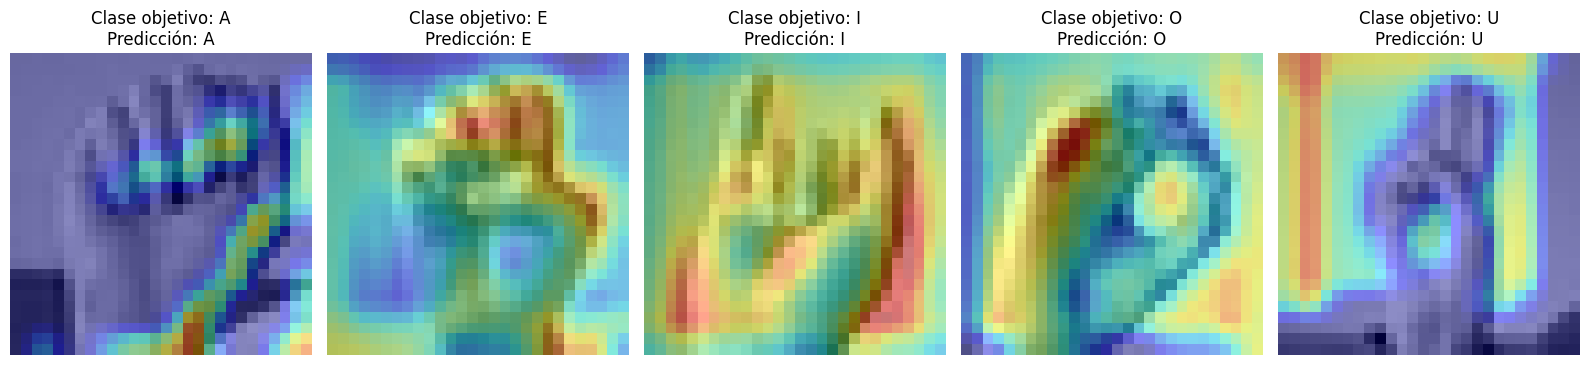

In [49]:
# Reconstruir el flujo simbólico usando las capas ya entrenadas
entrada_gradcam = tf.keras.Input(shape=(28, 28, 1))
x = entrada_gradcam
activacion_conv_final = None

for capa in model.layers:
    if isinstance(capa, tf.keras.layers.InputLayer):
        continue

    x = capa(x)

    if isinstance(capa, tf.keras.layers.Conv2D):
        activacion_conv_final = x

modelo_gradcam = tf.keras.Model(
    inputs=entrada_gradcam,
    outputs=[activacion_conv_final, x]
)


def generar_gradcam(imagen, clase_objetivo):
    imagen = tf.cast(imagen, tf.float32)

    with tf.GradientTape() as tape:
        activaciones, predicciones = modelo_gradcam(
            imagen, training=False
        )
        puntaje_clase = predicciones[:, clase_objetivo]

    gradientes = tape.gradient(puntaje_clase, activaciones)
    pesos = tf.reduce_mean(gradientes, axis=(1, 2), keepdims=True)

    mapa = tf.reduce_sum(pesos * activaciones, axis=-1)
    mapa = tf.maximum(mapa, 0)[0]
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)

    mapa = tf.image.resize(mapa[..., tf.newaxis], (28, 28))
    return tf.squeeze(mapa).numpy()


nombres_clases = ["A", "E", "I", "O", "U"]
rng = np.random.default_rng(29)
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for clase, ax in enumerate(axes):
    candidatos = np.where(y_test == clase)[0]
    indice = rng.choice(candidatos)

    imagen = X_test[indice:indice + 1]
    mapa = generar_gradcam(imagen, clase)
    prediccion = np.argmax(
        modelo_gradcam(imagen, training=False)[1].numpy(),
        axis=1
    )[0]

    ax.imshow(imagen[0].squeeze(), cmap="gray")
    ax.imshow(mapa, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(
        f"Clase objetivo: {nombres_clases[clase]}\n"
        f"Predicción: {nombres_clases[prediccion]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Se generó un mapa Grad-CAM para cada vocal usando una imagen del conjunto de prueba. En los cinco ejemplos seleccionados, la clase predicha coincide con la clase objetivo. Las zonas de mayor intensidad muestran las regiones de la imagen que más contribuyeron a la predicción de cada clase. La resolución de los mapas es baja porque se obtienen desde la última capa convolucional y luego se amplían para superponerlos a las imágenes.

# 8. Conclusiones y Análisis
E2\
La CNN obtuvo un mejor desempeño en el conjunto de prueba que el MLP: alcanzó 96,93 % de accuracy y 96,33 % de F1 macro, frente a 93,43 % y 92,26 %, respectivamente, para el MLP. Sin embargo, la CNN cuenta con 219.909 parámetros, aproximadamente el doble que el MLP, y su entrenamiento tomó 81,86 segundos, frente a 6,02 segundos.
La principal dificultad de la CNN fue reconocer la clase O: clasificó correctamente 196 de sus 246 imágenes y confundió las restantes con A, E o I. En cambio, reconoció correctamente todas las imágenes de prueba de A, E, I y U. Esto muestra un desempeño general alto, junto con una confusión que conviene considerar al analizar las clases.
La comparación se realizó usando los mismos datos, particiones, épocas y tamaño de lote. Como el MLP utilizó SGD y la CNN Adam, los resultados corresponden a los modelos con sus respectivas configuraciones y no permiten atribuir toda la diferencia únicamente a la arquitectura.